In [1]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/CPH100 Data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3.zip"
EXTRACT_DIR = "/content/CPH100_data"

!mkdir -p "$EXTRACT_DIR"
!unzip -o "$ZIP_PATH" -d "$EXTRACT_DIR"

Mounted at /content/drive
Archive:  /content/drive/MyDrive/CPH100 Data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3.zip
 extracting: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/LICENSE.txt  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/SHA256SUMS.txt  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/department.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/diagnosis.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/icd10_excluded.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/labs.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-pe

In [2]:
#import libraries
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier
import xgboost as xgb
plt.rcdefaults()
GLOBALSEED = 42

In [3]:
cd CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3

/content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3


In [4]:
#import schemas and data (around 1 minute to load)
# schemas = pd.read_csv("schema.csv")
operations = pd.read_csv("operations.csv")
# vitals = pd.read_csv("vitals.csv")

# department = pd.read_csv("department.csv")
# icd10_excluded = pd.read_csv("icd10_excluded.csv")
labs = pd.read_csv("labs.csv")
# medications = pd.read_csv("medications.csv")
# operations = pd.read_csv("operations.csv")
# parameters = pd.read_csv("parameters.csv")
# ward_vitals = pd.read_csv("ward_vitals.csv")
# diagnosis = pd.read_csv("diagnosis.csv")
operations.head()

,op_id,subject_id,hadm_id,case_id,opdate,age,sex,weight,height,race,...,admission_time,discharge_time,anstart_time,anend_time,cpbon_time,cpboff_time,icuin_time,icuout_time,inhosp_death_time,allcause_death_time
0,484069807,178742874,229842382,NaN,0,30,F,50.0,155.0,Asian,...,0,7195,1120.0,1235.0,NaN,NaN,NaN,NaN,NaN,NaN
1,446270725,158995752,257857903,NaN,0,70,M,45.0,170.0,Asian,...,0,70555,1345.0,1540.0,NaN,NaN,1550.0,19595.0,69860.0,106560.0
2,406892271,108553242,200664328,NaN,61920,50,F,70.0,165.0,Asian,...,0,178555,62170.0,62370.0,NaN,NaN,NaN,NaN,NaN,718560.0
3,478413008,133278262,277235295,NaN,0,35,F,55.0,NaN,Asian,...,0,5755,215.0,340.0,NaN,NaN,NaN,NaN,NaN,NaN
4,468516791,116924034,299190423,NaN,17280,45,F,45.0,150.0,Asian,...,0,25915,17950.0,18070.0,NaN,NaN,NaN,NaN,NaN,NaN


# XGBoost Recreation

In [5]:
working_table = operations.sort_values("orin_time", ascending=True).drop_duplicates(subset=['subject_id'])
print(f"Operation table # rows: {operations.shape[0]}")
print(f"Working table (only first operation) # rows: {working_table.shape[0]}")

Operation table # rows: 130960
Working table (only first operation) # rows: 99886


In [6]:
working_table["died30"] = (working_table['inhosp_death_time'] < (working_table['orout_time'] + 30 * 24 * 60)).astype("int") #credit: https://github.com/vitaldb/inspire/blob/main/gbm_mortality.py
# filter out asa >= 6
working_table = working_table[working_table["asa"] < 6]
print(f"Working table (only first operation, no ASA >= 6) # rows: {working_table.shape[0]}")
print(f"Number of deaths within 30 days + No ASA 6: {working_table['died30'].sum()}")
print(f"Percent of deaths within 30 days: {working_table['died30'].sum() / working_table.shape[0]}")

Working table (only first operation, no ASA >= 6) # rows: 97260
Number of deaths within 30 days + No ASA 6: 268
Percent of deaths within 30 days: 0.0027555007197203373


In [7]:
working_table['andur'] = (working_table['anend_time'] - working_table['anstart_time']).fillna(30)
working_table['bmi'] = (working_table['weight'] / (working_table['height'] / 100) ** 2).fillna(20)
# Fix: Only update the 'bmi' column for out-of-range values
working_table.loc[(working_table['bmi'] > 40) | (working_table['bmi'] < 5), 'bmi'] = 20

#labs table features credit: https://github.com/vitaldb/inspire/blob/main/gbm_mortality.py
for item in ('hb', 'platelet', 'aptt', 'wbc', 'ptinr', 'glucose', 'bun',
             'albumin', 'ast', 'alt', 'creatinine', 'sodium', 'potassium'):
  working_table = pd.merge_asof(working_table.sort_values("orin_time"), labs[labs['item_name'] == item].sort_values("chart_time"),
                              left_on='orin_time', right_on='chart_time', by='subject_id',
                              direction='nearest')
  working_table = working_table.rename(columns={'value': item})
  working_table = working_table.drop(columns=['item_name', 'chart_time'])
working_table.head()

working_table['sex'] = (working_table['sex'] == 'M').astype(int)

In [8]:
predictor = 'died30'
features = ['age', 'sex', 'emop', 'bmi', 'andur', 'hb', 'platelet', 'wbc', 'aptt',
            'ptinr', 'glucose', 'bun', 'albumin', 'ast', 'alt', 'creatinine', 'sodium', 'potassium']

X = working_table[features]
y = working_table[predictor]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# y_train, y_test = y_train[predictor], y_test[predictor]

In [ ]:
#same features, dif hyper params as original paper

model = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.01,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="auc",
    early_stopping_rounds=50,
    enable_categorical=True
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

best_val_auc = model.best_score
best_round = model.best_iteration

print(f"Best Validation AUC: {best_val_auc:.5f} at iteration {best_round}")
test_pred = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_pred)

print(f"Test AUC: {test_auc:.5f}")


Best Validation AUC: 0.96155 at iteration 386
Test AUC: 0.96155


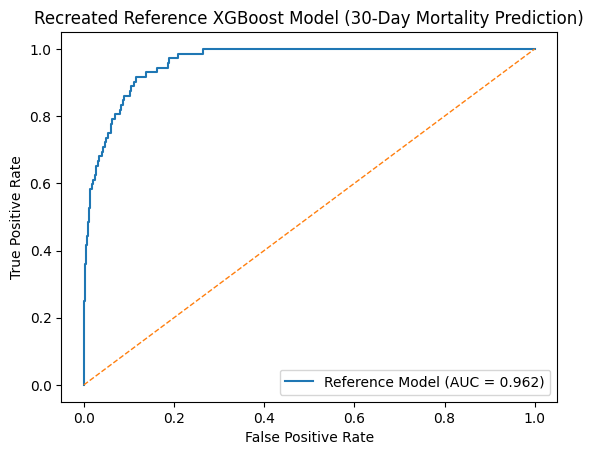

In [16]:
fpr_gbm, tpr_gbm, _ = roc_curve(y_test, test_pred)
plt.plot(fpr_gbm, tpr_gbm, label=f"Reference Model (AUC = {np.round(test_auc,3)})")
plt.plot([0, 1], [0, 1], lw=1, linestyle='--')
plt.title("Recreated Reference XGBoost Model (30-Day Mortality Prediction)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

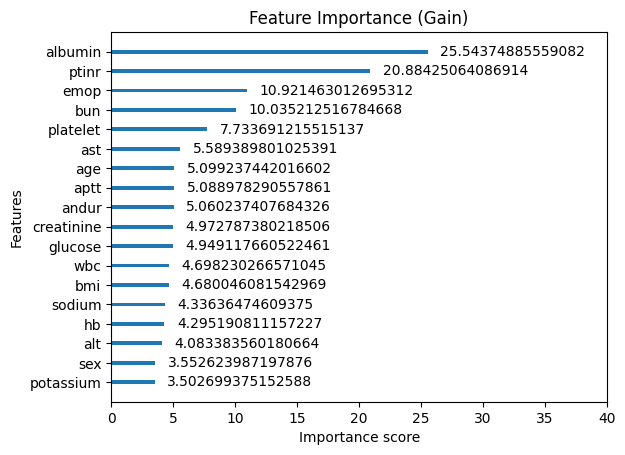

In [11]:
# plt.rcParams['figure.figsize'] = [14, 6]
xgb.plot_importance(model, importance_type='gain')
plt.grid(False)
plt.title("Feature Importance (Gain)")
plt.xlim(0, 40)
plt.rcdefaults()

/usr/local/lib/python3.12/dist-packages/xgboost/plotting.py:267: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` insetad. 
  warnings.warn(


<Axes: >

<Figure size 6000x6000 with 0 Axes>

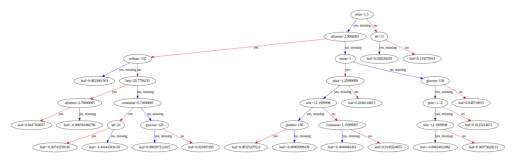

In [12]:
# plt.rcParams['figure.figsize'] = [30, 30]
# plt.rcParams['font.size'] = 14
plt.figure(figsize=(60, 60))
xgb.plot_tree(model, num_trees = 3)